In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the built-in dataset (handwritten digits 0-9)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# 2. Prepare the images (scale pixel values between 0 and 1)
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Build a simple CNN model
model = models.Sequential([
    layers.Reshape((28, 28, 1), input_shape=(28, 28)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax') # 10 outputs for digits 0-9
])

# 4. Compile & Train (takes ~30 seconds)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5)

# 5. Check final accuracy
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"\nModel Accuracy: {test_acc * 100:.2f}%")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/reshape.py:38: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 18ms/step - accuracy: 0.9492 - loss: 0.1709
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9816 - loss: 0.0604
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9872 - loss: 0.0422
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9908 - loss: 0.0297
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 18ms/step - accuracy: 0.9931 - loss: 0.0221
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9858 - loss: 0.0464

Model Accuracy: 98.58%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


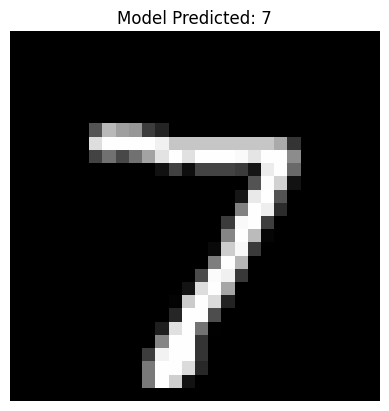

In [2]:
# Pick the first image from the test set
sample_image = x_test[0]

# Predict the number
prediction = model.predict(sample_image.reshape(1, 28, 28))
predicted_number = np.argmax(prediction)

# Show the image and result
plt.imshow(sample_image, cmap='gray')
plt.title(f"Model Predicted: {predicted_number}")
plt.axis('off')
plt.show()
